# Modelado del churn

**Proyecto Integrador 1 - The Outliers**

Entrenamiento, comparación y selección del modelo de churn sobre `churn_gold.customer_360`, a partir de las
decisiones de `01_eda_calidad.ipynb` (bitácora en `docs/eda_decisiones.md`). El modelo elegido es el que se
explica en `03_xai.ipynb`.

**Estructura del notebook**

| Sección | Título | Qué se hace |
|---|---|---|
| 1 | Datos | Carga de `customer_360`, pipeline de limpieza, partición del EDA y variables de cada escenario |
| 2 | Estrategia de validación | Validación cruzada estratificada sobre `train` y verificación de que no hay fugas |
| 3 | Referencias | Las referencias de la sección 6.2 del EDA, evaluadas con los mismos folds |
| 4 | Manejo del desbalance | Comparación de estrategias con el mismo modelo y los mismos folds |
| 5 | Tratamiento de las variables por modelo | Codificación, nulos, estandarización y multicolinealidad, auditoría del ROC-AUC y retiro de las variables con fuga |
| 6 | Entrenamiento y selección de modelos | Candidatos, optimización de hiperparámetros y elección del modelo final |
| 7 | Métricas más allá del ROC-AUC | Curvas ROC, precision-recall, ganancia acumulada y lift |
| 8 | Evaluación final en `test` | Una sola evaluación del modelo final con los clientes reservados |
| 9 | Caso de uso y limitaciones | Priorización por riesgo y valor, y limitaciones del modelo |
| 10 | Modelo final | Guardado del modelo de la sección 8 para `03_xai.ipynb` y la API |

**Escenarios** (decisiones 28 a 30 del EDA):

- **Principal:** las 7 variables de `customer_summary` sin fuga ni redundancia (`features.VARIABLES_ESCENARIO_PRINCIPAL`). En la sección 5.7 se retiran 3 por fuga y quedan 4.
- **Comparación:** las 51 variables de fuera de `customer_summary` (`features.variables_escenario_comparacion`). Se usa hasta la sección 6.1 (ver sección 6.2).

Las variables de cada escenario las fijó el EDA, así que este notebook no hace selección de variables, salvo retirar 3 por fuga en la sección 5.7.

**Metodología:** este notebook cubre las fases de **modelado** y **evaluación** de CRISP-DM.

## 1. Datos

### 1.1 Librerías y funciones

Importamos las librerías del modelado y el código compartido de `src/churn/`, el mismo que usó el EDA. Así el modelado
y la API aplican exactamente las mismas reglas:

| Módulo | Qué usamos de él |
|---|---|
| `churn.data` | Lectura de `customer_360` desde la caché de `data/`, normalización de tipos, partición train/test y la semilla |
| `churn.features` | Pipeline de limpieza, variables de cada escenario y columnas excluidas |
| `churn.eda` | La referencia `TasaPorGrupo` (sección 3) |

Los experimentos que tardan varios minutos (desbalance y Optuna) guardan sus resultados en `data/modelado/`, que está
en el `.gitignore`: si el archivo ya existe, lo leemos en lugar de volver a correr el experimento. Todo usa la semilla
del EDA, `SEMILLA = 42`.

In [1]:
import sys
import time
import warnings
from functools import partial
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import EditedNearestNeighbours, NearMiss, RandomUnderSampler, TomekLinks
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

import json
from importlib.metadata import version
import joblib

from churn import data, eda, features
from churn.features import LLAVE, OBJETIVO

SEMILLA = data.SEMILLA
DIR_RESULTADOS = data.DIR_DATOS / "modelado"   # cachés de los experimentos largos (ignoradas por git)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

Descargamos del bucket los resultados de `data/modelado`: experimentos, búsquedas de Optuna, predicciones y modelo final.
Las celdas que los usan los leen en lugar de recalcularlos, así cualquiera obtiene las cifras con las que se tomaron las
decisiones. Los archivos que ya existen no se reemplazan.


In [2]:
descargados, existentes = data.descargar_modelado()
print(f"archivos descargados de S3: {descargados}. Ya existían: {existentes}")

archivos descargados de S3: 0. Ya existían: 23


### 1.2 Carga de los datos, pipeline de limpieza y partición

Cargamos `customer_360` con la misma conexión y caché del EDA (sección 1.2) y le aplicamos el pipeline de limpieza
(sección 3.7 del EDA).

In [3]:
c360 = data.normalizar_tipos(data.cargar_customer_360(), features.COLUMNAS_FECHA)
limpio = features.crear_pipeline_limpieza().fit_transform(c360)

columnas_agregadas = [c for c in limpio.columns if c not in c360.columns]
columnas_quitadas = [c for c in c360.columns if c not in limpio.columns]
resumen_limpieza = pd.Series({
    "customer_360": f"{c360.shape[0]:,} filas x {c360.shape[1]} columnas",
    "después del pipeline de limpieza": f"{limpio.shape[0]:,} filas x {limpio.shape[1]} columnas",
    "columnas agregadas": ", ".join(columnas_agregadas),
    "columnas quitadas": ", ".join(columnas_quitadas),
}).to_frame("valor")
with pd.option_context("display.max_colwidth", None):
    display(resumen_limpieza)

,valor
customer_360,"500,000 filas x 70 columnas"
después del pipeline de limpieza,"500,000 filas x 68 columnas"
columnas agregadas,antiguedad_meses
columnas quitadas,"last_payment_date, payment_date_in_future, summary_vs_orders_mismatch"


El pipeline no elimina ningún cliente y deja las 68 columnas del EDA (sección 3.7).

Unimos la partición train/test del EDA (sección 4). Si `data/particion.parquet` no existe, `data.cargar_particion`
la vuelve a crear con el mismo procedimiento. `test` queda reservado hasta la sección 8.

In [4]:
particion = data.cargar_particion(limpio, OBJETIVO, LLAVE)
limpio = limpio.merge(particion, on=LLAVE, how="inner")
train = limpio[limpio["conjunto"] == "train"].drop(columns="conjunto").reset_index(drop=True)
test = limpio[limpio["conjunto"] == "test"].drop(columns="conjunto").reset_index(drop=True)

Como la partición se volvió a crear, comparamos sus cifras con las publicadas en la sección 4 del EDA.

In [5]:
# Cifras de la sección 4 de 01_eda_calidad.ipynb (porcentajes redondeados a 2 decimales)
REFERENCIA_EDA = {
    "clientes en train": 350_000, "clientes en test": 150_000, "clientes en ambos conjuntos": 0,
    "tasa de churn train (%)": 20.70, "tasa de churn test (%)": 20.70,
    "Basic train (%)": 55.08, "Basic test (%)": 54.87, "Silver train (%)": 24.92, "Silver test (%)": 25.09,
    "Gold train (%)": 15.01, "Gold test (%)": 15.02, "Platinum train (%)": 4.99, "Platinum test (%)": 5.02,
}

esta_ejecucion = {
    "clientes en train": len(train), "clientes en test": len(test),
    "clientes en ambos conjuntos": len(set(train[LLAVE]) & set(test[LLAVE])),
    "tasa de churn train (%)": round(train[OBJETIVO].mean() * 100, 2),
    "tasa de churn test (%)": round(test[OBJETIVO].mean() * 100, 2),
}
for nivel in ["Basic", "Silver", "Gold", "Platinum"]:
    for nombre, conjunto in [("train", train), ("test", test)]:
        esta_ejecucion[f"{nivel} {nombre} (%)"] = round((conjunto["membership_tier"] == nivel).mean() * 100, 2)

verificacion_particion = pd.DataFrame({"EDA (sección 4)": REFERENCIA_EDA, "esta ejecución": esta_ejecucion})
verificacion_particion["coincide"] = verificacion_particion["EDA (sección 4)"] == verificacion_particion["esta ejecución"]
print(f"clientes sin churn (fuera de la partición): {limpio[OBJETIVO].isna().sum()}")
# Se muestran como texto para que los conteos no aparezcan con decimales
verificacion_particion.astype({c: str for c in ["EDA (sección 4)", "esta ejecución"]}).replace(r"\.0$", "", regex=True)

clientes sin churn (fuera de la partición): 0


,EDA (sección 4),esta ejecución,coincide
clientes en train,350000,350000,True
clientes en test,150000,150000,True
clientes en ambos conjuntos,0,0,True
tasa de churn train (%),20.7,20.7,True
tasa de churn test (%),20.7,20.7,True
Basic train (%),55.08,55.08,True
Basic test (%),54.87,54.87,True
Silver train (%),24.92,24.92,True
Silver test (%),25.09,25.09,True
Gold train (%),15.01,15.01,True


- Todas las cifras coinciden con las del EDA.
- Todos los clientes tienen `churn`, así que ninguno queda fuera de la partición.

### 1.3 Variables de cada escenario

Tomamos las variables de los 2 escenarios de `src/churn/features.py` (sección 7 del EDA) y las separamos por tipo, porque
cada modelo las codifica de forma distinta. Verificamos que ninguna esté entre las columnas excluidas (llave, objetivo,
fechas, fuga, redundantes y descartadas por calidad).

In [6]:
ESCENARIOS = {
    "principal": features.VARIABLES_ESCENARIO_PRINCIPAL,
    "comparación": features.variables_escenario_comparacion(train),
}
COLUMNAS_EXCLUIDAS = {LLAVE, OBJETIVO, *features.COLUMNAS_FECHA, *features.COLUMNAS_FUGA,
                      *features.COLUMNAS_REDUNDANTES, *features.COLUMNAS_DESCARTADAS}
VARIABLES_RESUMEN = features.GRUPOS_VARIABLES["Resumen de cliente"]


def separar_por_tipo(df, variables):
    """Separa `variables` en numéricas, categóricas y booleanas según su tipo en `df` (ver data.normalizar_tipos)."""
    booleanas = [c for c in variables if pd.api.types.is_bool_dtype(df[c])]
    numericas = [c for c in variables if c not in booleanas and pd.api.types.is_numeric_dtype(df[c])]
    categoricas = [c for c in variables if c not in booleanas + numericas]
    return numericas, categoricas, booleanas


resumen_escenarios = {}
for nombre, variables in ESCENARIOS.items():
    numericas, categoricas, booleanas = separar_por_tipo(train, variables)
    resumen_escenarios[nombre] = {
        "variables": len(variables), "numéricas": len(numericas), "categóricas": len(categoricas),
        "booleanas": len(booleanas), "de customer_summary": len(set(variables) & set(VARIABLES_RESUMEN)),
        "excluidas que aparecen": len(set(variables) & COLUMNAS_EXCLUIDAS),
        "con nulos en train": int(train[variables].isna().any().sum()),
    }
pd.DataFrame(resumen_escenarios).T

,variables,numéricas,categóricas,booleanas,de customer_summary,excluidas que aparecen,con nulos en train
principal,7,7,0,0,7,0,0
comparación,51,36,12,3,0,0,11


- **Principal:** 7 variables numéricas, todas de `customer_summary` y sin nulos.
- **Comparación:** 51 variables (36 numéricas, 12 categóricas y 3 booleanas), ninguna de `customer_summary`.
- Ningún escenario incluye columnas excluidas.

Las 11 variables con nulos del escenario de comparación deberían ser los nulos estructurales de los clientes sin
pedidos o sin tickets (decisión 5 del EDA). Lo comprobamos, porque de eso depende cómo se representen en la sección 5.2.

In [7]:
variables_comparacion = ESCENARIOS["comparación"]
con_nulos = [c for c in variables_comparacion if train[c].isna().any()]
# Indicador de ausencia que explica cada grupo de nulos (pedidos o tickets)
indicador = {c: "has_orders" if c.startswith(("orders_", "days_since_last_order")) else "has_tickets" for c in con_nulos}

pd.DataFrame({
    "% nulos en train": [train[c].isna().mean() * 100 for c in con_nulos],
    "indicador": [indicador[c] for c in con_nulos],
    "nulo si y solo si el indicador es falso": [train[c].isna().equals(~train[indicador[c]].astype(bool)) for c in con_nulos],
}, index=con_nulos).round(2)

,% nulos en train,indicador,nulo si y solo si el indicador es falso
orders_amount_sum,13.5200,has_orders,True
orders_amount_avg,13.5200,has_orders,True
days_since_last_order,13.5200,has_orders,True
orders_discount_avg,13.5200,has_orders,True
orders_coupon_share,13.5200,has_orders,True
orders_delivery_days_avg,13.5200,has_orders,True
orders_customer_rating_avg,13.5200,has_orders,True
tickets_last_year_max,74.0800,has_tickets,True
tickets_resolution_hours_avg,74.0800,has_tickets,True
tickets_satisfaction_avg,74.0800,has_tickets,True


- Las variables de pedidos son nulas si y solo si `has_orders` es falso.
- Como los 2 indicadores ya están entre las variables, rellenar esos nulos con cualquier valor fijo no pierde información. Solo vamos a rellenar esos valores para la regresión logística.

## 2. Estrategia de validación

Usamos validación cruzada estratificada por `churn` con 5 folds sobre `train` y la semilla del EDA. Cada fold entrena con el 80 % de `train` y valida con el 20 % restante, y cada cliente queda en la validación de exactamente un fold. Ordenamos `train` por `customer_id` porque, sin ese orden cada integrante obtendría folds distintos con la misma semilla.

In [8]:
N_FOLDS = 5


def generar_folds(df, n_folds=N_FOLDS, semilla=SEMILLA):
    """Folds estratificados por el objetivo, con las posiciones de entrenamiento y validación de cada uno."""
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=semilla)
    return [{"fold": i + 1, "entrenamiento": ent, "validacion": val}
            for i, (ent, val) in enumerate(cv.split(df, df[OBJETIVO].astype(int)))]


train = train.sort_values(LLAVE).reset_index(drop=True)
y_train = train[OBJETIVO].astype(int)
folds = generar_folds(train)

pd.DataFrame([{
    "fold": f["fold"],
    "filas entrenamiento": len(f["entrenamiento"]),
    "filas validación": len(f["validacion"]),
    "tasa de churn entrenamiento (%)": y_train.iloc[f["entrenamiento"]].mean() * 100,
    "tasa de churn validación (%)": y_train.iloc[f["validacion"]].mean() * 100,
} for f in folds]).set_index("fold").round(2)

,filas entrenamiento,filas validación,tasa de churn entrenamiento (%),tasa de churn validación (%)
fold,,,,
1,280000,70000,20.7000,20.7000
2,280000,70000,20.7000,20.7000
3,280000,70000,20.7000,20.7000
4,280000,70000,20.7000,20.7000
5,280000,70000,20.7000,20.7000


Cada fold entrena con 280.000 clientes y valida con 70.000, y la tasa de churn es 20,70 % en todos.

Verificamos que no haya fugas entre entrenamiento y validación y que los folds no dependan del orden en que llegan las
filas. Para lo segundo, desordenamos `train` al azar, lo volvemos a ordenar, generamos otra vez los folds y comparamos
los clientes de cada validación.

In [9]:
clientes = train[LLAVE].to_numpy()
desordenado = train.sample(frac=1, random_state=0).reset_index(drop=True)
reordenado = desordenado.sort_values(LLAVE).reset_index(drop=True)
folds_desordenado, folds_reordenado = generar_folds(desordenado), generar_folds(reordenado)
veces_en_validacion = pd.Series(np.concatenate([clientes[f["validacion"]] for f in folds])).value_counts()


def misma_validacion(fold, otro_fold, otro_df):
    """Proporción de clientes de la validación de `fold` que también están en la validación de `otro_fold`."""
    validacion = set(clientes[fold["validacion"]])
    return len(validacion & set(otro_df[LLAVE].to_numpy()[otro_fold["validacion"]])) / len(validacion)


pd.DataFrame([{
    "fold": f["fold"],
    "clientes en entrenamiento y validación": len(set(clientes[f["entrenamiento"]]) & set(clientes[f["validacion"]])),
    "validación igual tras desordenar sin ordenar (%)": misma_validacion(f, d, desordenado) * 100,
    "validación igual tras desordenar y ordenar (%)": misma_validacion(f, r, reordenado) * 100,
} for f, d, r in zip(folds, folds_desordenado, folds_reordenado)]).set_index("fold").assign(
    **{"cada cliente en exactamente una validación": (veces_en_validacion == 1).all()
       and len(veces_en_validacion) == len(train)}).round(2)

,clientes en entrenamiento y validación,validación igual tras desordenar sin ordenar (%),validación igual tras desordenar y ordenar (%),cada cliente en exactamente una validación
fold,,,,
1,0,19.7800,100.0000,True
2,0,19.8800,100.0000,True
3,0,19.7600,100.0000,True
4,0,19.9800,100.0000,True
5,0,20.0300,100.0000,True


- Ningún cliente está a la vez en el entrenamiento y la validación de un fold, y cada cliente de `train` queda en la validación de exactamente un fold.
- Sin ordenar, al cambiar el orden de las filas solo coincide cerca del 20 % de cada validación, lo mismo que se esperaría por azar con 5 folds.

Definimos las funciones que usaremos para evaluar los modelos de aquí en adelante. Para cada fold entrenamos un modelo, predecimos su validación y calculamos el ROC-AUC y el PR-AUC.

In [10]:
def evaluar_modelo(modelo, variables, df=train, y=y_train, folds=folds, devolver_predicciones=False):
    """ROC-AUC y PR-AUC por fold de una copia de `modelo` entrenada con `variables`. Si `devolver_predicciones`,
    devuelve además la probabilidad de churn fuera de muestra de cada cliente de `df`."""
    resultados, prediccion = [], np.full(len(df), np.nan)
    for f in folds:
        X_ent, X_val = df.iloc[f["entrenamiento"]][variables], df.iloc[f["validacion"]][variables]
        y_ent, y_val = y.iloc[f["entrenamiento"]], y.iloc[f["validacion"]]
        probabilidad = clone(modelo).fit(X_ent, y_ent).predict_proba(X_val)[:, 1]
        prediccion[f["validacion"]] = probabilidad
        resultados.append({"fold": f["fold"], "roc_auc": roc_auc_score(y_val, probabilidad),
                           "pr_auc": average_precision_score(y_val, probabilidad)})
    resultados = pd.DataFrame(resultados).set_index("fold")
    return (resultados, prediccion) if devolver_predicciones else resultados


def resumir(resultados_por_modelo):
    """Promedio y desviación del ROC-AUC y promedio del PR-AUC de cada modelo, ordenados por ROC-AUC."""
    return pd.DataFrame({nombre: {"roc_auc": r["roc_auc"].mean(), "roc_auc_std": r["roc_auc"].std(),
                                  "pr_auc": r["pr_auc"].mean()}
                         for nombre, r in resultados_por_modelo.items()}).T.sort_values("roc_auc", ascending=False)

## 3. Baselines

| Referencia | Por qué se escogió | Escenario que la debe superar |
|---|---|---|
| **Aleatorio** | Linea base por defecto, si no se supera no vale la pena modelar | Ambos |
| **Tasa por `membership_tier`** | Es la regla que usaría el negocio sin un modelo: asignar a cada cliente la tasa de churn de su nivel de membresía en el entrenamiento | Comparación |
| **Tasa por `occupation` × `education`** | Mejor regla que se puede armar con el perfil del cliente según el EDA. | Comparación |
| **Solo `last_purchase_days`** | Una regresión logística con la variable de mayor AUC univariado (sección 5.2 del EDA). Para revisar si usar las 7 variables mejora lo que ya logra la mejor de ellas sola | Principal |

Las 3 primeras usan variables que pertenecen al escenario de comparación, y la última una del principal. Por eso cada
escenario se contrasta con las suyas: comparar el principal con el azar no diría nada, porque cualquiera de sus variables ya lo supera. Esto aplica al escenario principal con sus 7 variables: desde la sección 5.7, `last_purchase_days` ya no está y el contraste es con el azar.

In [11]:
REFERENCIAS = {
    "aleatorio": (DummyClassifier(strategy="prior"), ["membership_tier"]),
    "tasa por membership_tier": (eda.TasaPorGrupo(["membership_tier"]), ["membership_tier"]),
    "tasa por occupation × education": (eda.TasaPorGrupo(["occupation", "education"]), ["occupation", "education"]),
    "solo last_purchase_days": (make_pipeline(StandardScaler(), LogisticRegression()), ["last_purchase_days"]),
}

resultados_referencias = {nombre: evaluar_modelo(modelo, variables) for nombre, (modelo, variables) in REFERENCIAS.items()}
tabla_referencias = resumir(resultados_referencias)
tabla_referencias.round(4)

,roc_auc,roc_auc_std,pr_auc
solo last_purchase_days,0.8647,0.0021,0.6775
tasa por membership_tier,0.5003,0.0030,0.2071
tasa por occupation × education,0.5002,0.0027,0.2059
aleatorio,0.5000,0.0000,0.2070


- Se obtienen cifras prácticamente iguales a las del EDA.
- Las referencias por categorías quedan igual que el azar (ROC-AUC de 0,5002 y 0,5003). El escenario de comparación se contrasta con ellas.
- Solo con `last_purchase_days` el ROC-AUC llega a 0,8647 y el PR-AUC a 0,6775. Es la referencia que debe superar el escenario principal con sus 7 variables (ver sección 5.7).

**Referencia pública (Kaggle).** El único notebook público comparable es el del autor del dataset,
[*Customer Churn Prediction End-to-End ML*](https://www.kaggle.com/code/kuldeepjangra/customer-churn-prediction-end-to-end-ml). Con XGBoost y una partición 80/20 obtiene **ROC-AUC de 0,5035 y
PR-AUC de 0,2088**. Solo se cita, no se replica. Es comparable con el escenario de comparación, porque no usa ninguna
variable de `customer_summary` como predictora.

| Escenario | Referencias que debe superar |
|---|---|
| Principal | Solo `last_purchase_days`: ROC-AUC de 0,8647, con las 7 variables (ver sección 5.7) |
| Comparación | Las tasas por categorías y el azar. Deseable también la referencia pública (0,5035) |

## 4. Manejo del desbalance

Vamos a comparar estrategias de remuestreo con el mismo modelo y los mismos folds para ver el efecto de cada una:

- Random undersampling 
- Random oversampling 
- SMOTE
- NearMiss
- ENN
- Tomek links
- SMOTE + Tomek links y SMOTE + ENN
- ENN + random undersampling

Las estrategias que fijan una proporción se prueban con 30 %, 40 % y 50 % de positivos después del remuestreo.

Usamos un random forest con pocos árboles y hojas de al menos 20 clientes. Además del ROC-AUC y el PR-AUC
registramos el Brier score de las probabilidades sin corregir, porque al cambiar la proporción de clases el modelo deja de estar calibrado.

In [12]:
PROPORCIONES = [0.3, 0.4, 0.5]


def razon(p):
    """Proporción de positivos después del remuestreo -> razón positivos/negativos de imbalanced-learn."""
    return p / (1 - p)


def rf_rapido():
    return RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_features="sqrt", n_jobs=-1,
                                  random_state=SEMILLA)


# Cada configuración: (estrategia, proporción, lista de muestreadores que se aplican en orden)
configuraciones = [
    ("sin remuestreo", None, []),
    ("ENN", None, [EditedNearestNeighbours(n_jobs=-1)]),
    ("Tomek links", None, [TomekLinks(n_jobs=-1)]),
]
for p in PROPORCIONES:
    configuraciones += [
        ("random undersampling", p, [RandomUnderSampler(sampling_strategy=razon(p), random_state=SEMILLA)]),
        ("random oversampling", p, [RandomOverSampler(sampling_strategy=razon(p), random_state=SEMILLA)]),
        ("SMOTE", p, [SMOTE(sampling_strategy=razon(p), random_state=SEMILLA)]),
        ("NearMiss", p, [NearMiss(sampling_strategy=razon(p), n_jobs=-1)]),
        ("SMOTE + Tomek links", p, [SMOTE(sampling_strategy=razon(p), random_state=SEMILLA), TomekLinks(n_jobs=-1)]),
        ("SMOTE + ENN", p, [SMOTE(sampling_strategy=razon(p), random_state=SEMILLA), EditedNearestNeighbours(n_jobs=-1)]),
        ("ENN + random undersampling", p, [EditedNearestNeighbours(n_jobs=-1),
                                           RandomUnderSampler(sampling_strategy=razon(p), random_state=SEMILLA)]),
    ]
print(f"configuraciones a evaluar: {len(configuraciones)} x {len(folds)} folds")

configuraciones a evaluar: 24 x 5 folds


Definimos el experimento. Los métodos basados en vecinos necesitan variables numéricas, sin nulos y en la misma escala, así que en cada fold las categóricas pasan a enteros, los nulos estructurales a 0 y todo se estandariza. Como tarda varios minutos, guardamos los resultados en `data/modelado/`.

In [13]:
def a_numerico(ent, val, variables):
    """Variables numéricas, sin nulos y estandarizadas para los métodos basados en vecinos, aprendidas solo de `ent`."""
    _, categoricas, _ = separar_por_tipo(ent, variables)
    X_ent, X_val = ent[variables].copy(), val[variables].copy()
    for c in categoricas:
        categorias = sorted(X_ent[c].dropna().unique())
        X_ent[c] = pd.Categorical(X_ent[c], categories=categorias).codes
        X_val[c] = pd.Categorical(X_val[c], categories=categorias).codes   # -1 si la categoría no está en `ent`
    X_ent, X_val = X_ent.astype(float).fillna(0), X_val.astype(float).fillna(0)
    escalador = StandardScaler().fit(X_ent)
    return escalador.transform(X_ent), escalador.transform(X_val)


def correr_experimento_desbalance(variables):
    filas = []
    for f in folds:
        X_ent, X_val = a_numerico(train.iloc[f["entrenamiento"]], train.iloc[f["validacion"]], variables)
        y_ent, y_val = y_train.iloc[f["entrenamiento"]].to_numpy(), y_train.iloc[f["validacion"]].to_numpy()

        for estrategia, proporcion, muestreadores in configuraciones:
            inicio = time.perf_counter()
            X_rem, y_rem = X_ent, y_ent
            for muestreador in muestreadores:
                # Si ENN ya dejó más positivos que la proporción pedida, el undersampling no tiene nada que quitar
                if isinstance(muestreador, RandomUnderSampler) and y_rem.mean() >= proporcion:
                    continue
                X_rem, y_rem = clone(muestreador).fit_resample(X_rem, y_rem)
            probabilidad = rf_rapido().fit(X_rem, y_rem).predict_proba(X_val)[:, 1]
            filas.append({"estrategia": estrategia, "proporcion": proporcion, "fold": f["fold"],
                          "filas_entrenamiento": len(y_rem), "pct_positivos": y_rem.mean() * 100,
                          "segundos": time.perf_counter() - inicio,
                          "roc_auc": roc_auc_score(y_val, probabilidad),
                          "pr_auc": average_precision_score(y_val, probabilidad),
                          "brier": brier_score_loss(y_val, probabilidad)})
        print(f"fold {f['fold']} de {len(folds)} completado")
    return pd.DataFrame(filas)


def experimento_desbalance(variables, ruta):
    """Lee los resultados guardados en `ruta` o, si no existen, corre el experimento y los guarda."""
    if ruta.exists():
        return pd.read_csv(ruta)
    resultados = correr_experimento_desbalance(variables)
    resultados.to_csv(ruta, index=False)
    return resultados


def resumir_desbalance(resultados):
    """Promedio de los folds por estrategia y proporción, con la diferencia de ROC-AUC frente a no remuestrear."""
    tabla = (resultados
             .assign(proporcion=resultados["proporcion"].map(lambda p: "-" if pd.isna(p) else f"{p:.0%}"))
             .groupby(["estrategia", "proporcion"])
             .agg(roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"), pr_auc=("pr_auc", "mean"),
                  brier=("brier", "mean"), pct_positivos=("pct_positivos", "mean"),
                  filas_entrenamiento=("filas_entrenamiento", "mean"), segundos=("segundos", "mean"))
             .sort_values("roc_auc", ascending=False))
    tabla.insert(1, "diferencia_vs_sin_remuestreo", tabla["roc_auc"] - tabla.loc[("sin remuestreo", "-"), "roc_auc"])
    return tabla


FORMATO_DESBALANCE = {"roc_auc": "{:.5f}", "roc_auc_std": "{:.5f}", "diferencia_vs_sin_remuestreo": "{:+.5f}",
                      "pr_auc": "{:.5f}", "brier": "{:.4f}", "pct_positivos": "{:.1f}",
                      "filas_entrenamiento": "{:,.0f}", "segundos": "{:.1f}"}

### 4.1 Escenario principal

Promediamos los 5 folds de cada estrategia y proporción, y calculamos su diferencia de ROC-AUC con el random forest
sin remuestreo.

In [14]:
resultados_desbalance = experimento_desbalance(ESCENARIOS["principal"], DIR_RESULTADOS / "resultados_desbalance.csv")
tabla_desbalance = resumir_desbalance(resultados_desbalance)
tabla_desbalance.style.format(FORMATO_DESBALANCE)

- Todas las estrategias quedan muy similar con no remustrear, de hecho, todas las diferencias están muy por debajo del margen de empate de 0,001 (sección 6.1 del EDA).
- Las que eliminan negativos (random undersampling, ENN y sus combinaciones) son las que más bajan, aunque por poco,
  y empeoran el Brier (hasta 0,0161 frente a 0,0074). Las de sobremuestreo dejan el Brier casi igual (0,0070 a 0,0078).
- Como hay empate, decide la parsimonia: **no remuestreamos**. Así se entrena con los datos tal como son y las probabilidades no necesitan corrección por el cambio de proporción.

### 4.2 Escenario de comparación

El escenario de comparación como habíamos visto antes (sección 6.3 del EDA) no tiene poder predictivo. Repetimos el experimento con sus 51 variables, solo como prueba de que ninguna estrategia de remuestreo potencia su capacidad.

In [15]:
resultados_desbalance_comparacion = experimento_desbalance(
    ESCENARIOS["comparación"], DIR_RESULTADOS / "resultados_desbalance_comparacion.csv")
tabla_desbalance_comparacion = resumir_desbalance(resultados_desbalance_comparacion)
tabla_desbalance_comparacion.style.format(FORMATO_DESBALANCE)

- Todas las estrategias quedan entre 0,497 y 0,502 de ROC-AUC, en el rango del azar y por debajo de la referencia pública (0,5035, sección 3). Remuestrear no aumenta el poder predictivo.
- Se confirma la decisión del 4.1: **no remuestreamos en ningún escenario**.

## 5. Tratamiento de las variables por modelo

Las variables de cada escenario ya están fijadas (sección 1.3). Definimos un pipeline de preparación por escenario, con
una variante para la regresión logística y otra para los modelos de árboles, y resolvemos los puntos que la sección 7
del EDA dejó para el modelado. La preparación va dentro de cada modelo, así que se ajusta solo con el entrenamiento de
cada fold.

### 5.1 Codificación y escala

| Modelo | Numéricas | Categóricas y booleanas |
|---|---|---|
| Regresión logística | Nulos estructurales a 0 y estandarización, para que los coeficientes sean comparables | One-hot sin la primera categoría, para que los coeficientes queden identificados |
| Random forest y XGBoost | Sin cambios, admiten nulos | Enteros, porque los árboles no necesitan one-hot |
| EBM | Sin cambios | Sin cambios, porque el EBM recibe las categorías como texto |

Definimos una función que arma la preparación de cada tipo de modelo. Los parámetros `relleno` y `estandarizar` se
deciden en las secciones 5.2 y 5.3.

In [16]:
def crear_preparacion(variables, tipo, relleno=0, estandarizar=True):
    """Preparación de `variables` para un tipo de modelo ("lineal", "arboles" o "ebm"), según la tabla de la sección 5.1.
    `relleno` es el valor de los nulos estructurales y `estandarizar` aplica StandardScaler (solo "lineal")."""
    numericas, categoricas, booleanas = separar_por_tipo(train, variables)
    if tipo == "ebm":
        return "passthrough"
    if tipo == "arboles":
        columnas = [("numericas", "passthrough", numericas),
                    ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
                     categoricas + booleanas)]
        return ColumnTransformer(columnas, verbose_feature_names_out=False).set_output(transform="pandas")

    imputador = (SimpleImputer(strategy="median") if relleno == "mediana"
                 else SimpleImputer(strategy="constant", fill_value=relleno))
    columnas = [("numericas", imputador, numericas),
                ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                 categoricas + booleanas)]
    pasos = [ColumnTransformer(columnas, verbose_feature_names_out=False)]
    if estandarizar:
        pasos.append(StandardScaler())
    return make_pipeline(*pasos).set_output(transform="pandas")

### 5.2 Nulos estructurales

Solo el escenario de comparación tiene nulos (sección 1.3). Como los indicadores `has_orders` y `has_tickets` están entre las variables, el valor de relleno no debería cambiar las predicciones de la logística. Lo comprobamos en el primer fold, rellenando con 0 y con la mediana del entrenamiento.

In [17]:
f = folds[0]
variables = ESCENARIOS["comparación"]
X_ent, X_val = train.iloc[f["entrenamiento"]][variables], train.iloc[f["validacion"]][variables]

predicciones_relleno = {}
for relleno in [0, "mediana"]:
    # C infinito = sin penalización
    modelo = make_pipeline(crear_preparacion(variables, "lineal", relleno=relleno),
                           LogisticRegression(C=np.inf, max_iter=2000))
    predicciones_relleno[relleno] = modelo.fit(X_ent, y_train.iloc[f["entrenamiento"]]).predict_proba(X_val)[:, 1]

diferencia = np.abs(predicciones_relleno[0] - predicciones_relleno["mediana"])
print(f"diferencia de probabilidad entre rellenar con 0 y con la mediana: máxima {diferencia.max():.4f}, "
      f"media {diferencia.mean():.5f}")

diferencia de probabilidad entre rellenar con 0 y con la mediana: máxima 0.0030, media 0.00033


Rellenamos con 0 ya que la diferencia no es significativa

### 5.3 Estandarización

Comprobamos si conviene estandarizar las numéricas de la logística (sección 5.1), comparando con y sin `StandardScaler` en los 5 folds, con ridge y C = 1. Sin estandarizar la logística tarda varios minutos, así que guardamos los resultados.

In [18]:
MAX_ITERACIONES = 2000


def correr_experimento_estandarizacion():
    filas = []
    for escenario, variables in ESCENARIOS.items():
        for estandarizar in [True, False]:
            modelo = make_pipeline(crear_preparacion(variables, "lineal", estandarizar=estandarizar),
                                   LogisticRegression(max_iter=MAX_ITERACIONES))
            for f in folds:
                X_ent, X_val = train.iloc[f["entrenamiento"]][variables], train.iloc[f["validacion"]][variables]
                y_ent, y_val = y_train.iloc[f["entrenamiento"]], y_train.iloc[f["validacion"]]
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", ConvergenceWarning)   # se reporta con las iteraciones
                    ajustado = clone(modelo).fit(X_ent, y_ent)
                probabilidad = ajustado.predict_proba(X_val)[:, 1]
                filas.append({"escenario": escenario, "estandarizar": estandarizar, "fold": f["fold"],
                              "iteraciones": int(ajustado[-1].n_iter_[0]),
                              "roc_auc": roc_auc_score(y_val, probabilidad),
                              "pr_auc": average_precision_score(y_val, probabilidad)})
    return pd.DataFrame(filas)


ruta = DIR_RESULTADOS / "resultados_estandarizacion.csv"
if ruta.exists():
    resultados_estandarizacion = pd.read_csv(ruta)
else:
    resultados_estandarizacion = correr_experimento_estandarizacion()
    resultados_estandarizacion.to_csv(ruta, index=False)

(resultados_estandarizacion
 .assign(sin_converger=resultados_estandarizacion["iteraciones"] >= MAX_ITERACIONES)
 .groupby(["escenario", "estandarizar"])
 .agg(roc_auc=("roc_auc", "mean"), roc_auc_std=("roc_auc", "std"), pr_auc=("pr_auc", "mean"),
      iteraciones_max=("iteraciones", "max"), folds_sin_converger=("sin_converger", "sum"))
 .style.format({"roc_auc": "{:.5f}", "roc_auc_std": "{:.5f}", "pr_auc": "{:.5f}"}))

- **Principal:** el ROC-AUC casi no cambia (1,00000 con estandarización y 0,99998 sin ella), pero sin estandarizar la
  logística necesita hasta 1.729 iteraciones en lugar de 23.
- **Comparación:** no hay señal en ningún caso (0,4990 y 0,4996), y sin estandarizar no converge en ningún fold con el límite de 2000.

Decidimos estandarizar porque la logística converge más rápido y para comparar coeficientes. No se aplicará ninguna otra transformación a las variables asimétricas.

### 5.4 Multicolinealidad

Revisamos si el VIF de `total_spent` (decisión 31 del EDA) y el par `tickets_satisfaction_avg` y
`tickets_satisfaction_min` (decisión 36) afectan la lectura de los coeficientes de la regresión logística. Comparamos
los coeficientes estandarizados de los 5 folds sin penalización y con ridge, con 2 valores de C (el valor final se
optimiza en la sección 6.2).

In [19]:
PENALIZACIONES = {"sin penalización": LogisticRegression(C=np.inf, max_iter=5000),
                  "ridge C = 1": LogisticRegression(C=1, max_iter=5000),
                  "ridge C = 0,01": LogisticRegression(C=0.01, max_iter=5000)}
VARIABLES_COLINEALES = {"principal": ["total_spent", "summary_total_orders", "average_order_value"],
                        "comparación": ["tickets_satisfaction_avg", "tickets_satisfaction_min"]}

filas = []
for escenario, variables in ESCENARIOS.items():
    for nombre, logistica in PENALIZACIONES.items():
        coeficientes = []
        for f in folds:
            modelo = make_pipeline(crear_preparacion(variables, "lineal"), clone(logistica))
            modelo.fit(train.iloc[f["entrenamiento"]][variables], y_train.iloc[f["entrenamiento"]])
            coeficientes.append(pd.Series(modelo[-1].coef_[0], index=modelo[0].get_feature_names_out()))
        coeficientes = pd.DataFrame(coeficientes)
        for variable in VARIABLES_COLINEALES[escenario]:
            filas.append({"escenario": escenario, "modelo": nombre, "variable": variable,
                          "coeficiente medio": coeficientes[variable].mean(),
                          "desviación entre folds": coeficientes[variable].std(),
                          "cambia de signo": coeficientes[variable].min() < 0 < coeficientes[variable].max(),
                          "mayor |coeficiente| del modelo": coeficientes.abs().max().max()})
pd.DataFrame(filas).set_index(["escenario", "modelo", "variable"]).round(3)

coeficiente medio  \
escenario   modelo           variable                                      
principal   sin penalización total_spent                          0.4340   
                             summary_total_orders                -0.2270   
                             average_order_value                 -0.3050   
            ridge C = 1      total_spent                          0.0360   
                             summary_total_orders                -0.0800   
                             average_order_value                 -0.0280   
            ridge C = 0,01   total_spent                          0.0000   
                             summary_total_orders                -0.2600   
                             average_order_value                 -0.0030   
comparación sin penalización tickets_satisfaction_avg             0.0060   
                             tickets_satisfaction_min             0.0070   
            ridge C = 1      tickets_satisfaction_avg             0.0060   
                             tickets_satisfaction_min             0.0070   
            ridge C = 0,01   tickets_satisfaction_avg             0.0060   
                             tickets_satisfaction_min             0.0070   

                                                       desviación entre folds  \
escenario   modelo           variable                                           
principal   sin penalización total_spent                               0.2820   
                             summary_total_orders                      0.4420   
                             average_order_value                       0.2220   
            ridge C = 1      total_spent                               0.0100   
                             summary_total_orders                      0.0110   
                             average_order_value                       0.0090   
            ridge C = 0,01   total_spent                               0.0050   
                             summary_total_orders                      0.0030   
                             average_order_value                       0.0040   
comparación sin penalización tickets_satisfaction_avg                  0.0020   
                             tickets_satisfaction_min                  0.0030   
            ridge C = 1      tickets_satisfaction_avg                  0.0020   
                             tickets_satisfaction_min                  0.0030   
            ridge C = 0,01   tickets_satisfaction_avg                  0.0020   
                             tickets_satisfaction_min                  0.0030   

                                                       cambia de signo  \
escenario   modelo           variable                                    
principal   sin penalización total_spent                         False   
                             summary_total_orders                 True   
                             average_order_value                 False   
            ridge C = 1      total_spent                         False   
                             summary_total_orders                False   
                             average_order_value                 False   
            ridge C = 0,01   total_spent                          True   
                             summary_total_orders                False   
                             average_order_value                  True   
comparación sin penalización tickets_satisfaction_avg            False   
                             tickets_satisfaction_min            False   
            ridge C = 1      tickets_satisfaction_avg            False   
                             tickets_satisfaction_min            False   
            ridge C = 0,01   tickets_satisfaction_avg            False   
                             tickets_satisfaction_min            False   

                                                       mayor |coeficiente| del modelo  
escenario   modelo           variable

- **Principal, sin penalización:** los coeficientes de `total_spent`, `summary_total_orders` y `average_order_value`
  varían mucho entre folds y `summary_total_orders` cambia de signo. El mayor coeficiente del modelo
  llega a 728, porque las clases están casi separadas (decisión 35 del EDA). Así no se pueden leer.
- **Principal, con ridge:** los coeficientes se estabilizan (desviación cercana a 0,01 o menor), pero su reparto entre las 3
  variables depende de C. Con C = 0,01 casi todo el efecto pasa a `summary_total_orders`. Por eso las 3 se interpretan
  juntas, como el efecto del gasto, y no una por una.
- **Comparación:** el par de satisfacción es estable con y sin penalización, y sus coeficientes son casi 0, como
  corresponde a variables sin señal.
- Conservamos las variables. La logística ridge es la que se usa para leer coeficientes, y su C se optimiza en la
  sección 6.2.

### 5.5 Pipelines de preparación de cada escenario

Con las decisiones de 5.1 a 5.4 fijamos la preparación de cada escenario. En la sección 6 cada modelo se arma como
`make_pipeline(PREPARACION[escenario][tipo], modelo)`. Verificamos en el primer fold que la preparación produzca solo
columnas numéricas y, para la logística, sin nulos.

In [20]:
TIPOS_MODELO = ["lineal", "arboles", "ebm"]
PREPARACION = {escenario: {tipo: crear_preparacion(variables, tipo) for tipo in TIPOS_MODELO}
               for escenario, variables in ESCENARIOS.items()}

f = folds[0]
verificacion_preparacion = []
for escenario, variables in ESCENARIOS.items():
    for tipo in ["lineal", "arboles"]:
        preparacion = clone(PREPARACION[escenario][tipo]).fit(train.iloc[f["entrenamiento"]][variables])
        X_preparado = preparacion.transform(train.iloc[f["validacion"]][variables])
        verificacion_preparacion.append({
            "escenario": escenario, "tipo de modelo": tipo, "variables de entrada": len(variables),
            "columnas preparadas": X_preparado.shape[1],
            "columnas con nulos": int(X_preparado.isna().any().sum()),
            "todas numéricas": all(pd.api.types.is_numeric_dtype(X_preparado[c]) for c in X_preparado.columns),
        })
pd.DataFrame(verificacion_preparacion).set_index(["escenario", "tipo de modelo"])

variables de entrada  columnas preparadas  \
escenario   tipo de modelo                                              
principal   lineal                             7                    7   
            arboles                            7                    7   
comparación lineal                            51                   85   
            arboles                           51                   51   

                            columnas con nulos  todas numéricas  
escenario   tipo de modelo                                       
principal   lineal                           0             True  
            arboles                          0             True  
comparación lineal                           0             True  
            arboles                         11             True

| Escenario | Regresión logística | Random forest y XGBoost | EBM |
|---|---|---|---|
| Principal | 7 numéricas estandarizadas | 7 numéricas sin cambios | Sin cambios |
| Comparación | 85 columnas: nulos a 0, one-hot y estandarización | 51 columnas: categóricas y booleanas a enteros, y los nulos de 11 columnas sin cambios | Sin cambios |

Todas las columnas preparadas son numéricas, y la preparación de la logística no deja nulos.

### 5.6 Auditoría del ROC-AUC del escenario principal

La logística alcanza un ROC-AUC de 1,0 en el escenario principal (sección 5.3). Antes de entrenar los candidatos revisamos
si se debe a sobreajuste, a un error en la validación o a la forma en que se construyó la etiqueta (decisiones 6 y 29 del
EDA). Seguimos evaluando todo en train.

Primero comparamos el ROC-AUC en entrenamiento y en validación, y repetimos la validación con la etiqueta permutada. Si hubiera sobreajuste, el entrenamiento superaría a la validación. Si hubiera un error en la validación, la etiqueta permutada seguiría dando un valor alto.


In [21]:
variables = ESCENARIOS["principal"]
logistica_principal = make_pipeline(PREPARACION["principal"]["lineal"], LogisticRegression(max_iter=5000))

# Evaluar sobre las mismas filas del entrenamiento de cada fold da el ROC-AUC de entrenamiento
folds_entrenamiento = [{**f, "validacion": f["entrenamiento"]} for f in folds]
y_permutada = pd.Series(np.random.default_rng(SEMILLA).permutation(y_train.to_numpy()), index=y_train.index)

auditoria = {"validación": evaluar_modelo(logistica_principal, variables),
             "entrenamiento": evaluar_modelo(logistica_principal, variables, folds=folds_entrenamiento),
             "validación con etiqueta permutada": evaluar_modelo(logistica_principal, variables, y=y_permutada)}
resumir(auditoria).style.format("{:.5f}")

,roc_auc,roc_auc_std,pr_auc
entrenamiento,1.00000,0.00000,1.00000
validación,1.00000,0.00000,1.00000
validación con etiqueta permutada,0.50203,0.00192,0.20828


Ahora medimos cuántas variables hacen falta para llegar a ese valor, primero con conjuntos fijos a partir de las 3
variables de la decisión 29 del EDA y después dejando que Lasso elija. Las variables retenidas por Lasso se obtienen con
todo `train`, y su ROC-AUC con los folds.


In [22]:
VARIABLES_ETIQUETA = features.COLUMNAS_FUGA_ETIQUETA
CONJUNTOS = {"las 7 variables": ESCENARIOS["principal"],
             "las 3 de la decisión 29": VARIABLES_ETIQUETA,
             "last_purchase_days y return_rate": VARIABLES_ETIQUETA[:2],
             "solo last_purchase_days": VARIABLES_ETIQUETA[:1]}

resultados_conjuntos = {}
for nombre, conjunto in CONJUNTOS.items():
    modelo = make_pipeline(crear_preparacion(conjunto, "lineal"), LogisticRegression(max_iter=5000))
    resultados_conjuntos[nombre] = evaluar_modelo(modelo, conjunto)
resumir(resultados_conjuntos).style.format("{:.5f}")

,roc_auc,roc_auc_std,pr_auc
las 3 de la decisión 29,1.00000,0.00000,1.00000
las 7 variables,1.00000,0.00000,1.00000
last_purchase_days y return_rate,0.98894,0.00037,0.95317
solo last_purchase_days,0.86472,0.00213,0.67752


In [23]:
variables = ESCENARIOS["principal"]
filas = []
for C in [1, 0.01, 0.001, 0.0001, 0.00003, 0.00001]:
    lasso = make_pipeline(PREPARACION["principal"]["lineal"],
                          LogisticRegression(C=C, l1_ratio=1, solver="liblinear", max_iter=2000))
    resultado = evaluar_modelo(lasso, variables)
    coeficientes = pd.Series(clone(lasso).fit(train[variables], y_train)[-1].coef_[0], index=variables)
    retenidas = coeficientes[coeficientes != 0].index.tolist()
    filas.append({"C": C, "variables retenidas": len(retenidas), "roc_auc": resultado["roc_auc"].mean(),
                  "cuáles": ", ".join(retenidas) or "ninguna"})
pd.DataFrame(filas).set_index("C").style.format({"roc_auc": "{:.5f}"}).format_index("{:g}")

,variables retenidas,roc_auc,cuáles
C,,,
1,7,1.00000,"summary_total_orders, total_spent, average_order_value, total_returns, return_rate, last_purchase_days, purchase_frequency"
0.01,4,0.99999,"summary_total_orders, return_rate, last_purchase_days, purchase_frequency"
0.001,4,0.99959,"summary_total_orders, return_rate, last_purchase_days, purchase_frequency"
0.0001,4,0.99232,"summary_total_orders, return_rate, last_purchase_days, purchase_frequency"
3e-05,2,0.98789,"return_rate, last_purchase_days"
1e-05,0,0.50000,ninguna


- **No es sobreajuste ni un error de validación:** entrenamiento y validación dan 1, y con la etiqueta permutada el ROC-AUC cae a 0,5020.
- **Bastan 3 variables:** `last_purchase_days`, `return_rate` y `purchase_frequency` dan el mismo 1,0000 que las 7. Sin `purchase_frequency` baja a 0,9889. Lasso conserva esas 3 y `summary_total_orders` hasta C = 0,0001.
- **Origen:** el resultado es coherente con una etiqueta calculada a partir de estas variables (decisiones 6 y 29 del EDA), aunque sin el código del generador no queda demostrado.

El modelo con las 7 variables reproduce esa regla, así que su ROC-AUC no mide la capacidad de predecir el abandono real. Por eso retiramos estas 3 variables en la sección 5.7.


### 5.7 Escenario principal sin las variables de la etiqueta

Suponemos que `last_purchase_days`, `return_rate` y `purchase_frequency` son las variables con las que se construyó la
etiqueta (sección 5.6) y las retiramos por fuga. Validamos el cambio con el random forest de la sección 4 y los mismos
folds. Desde aquí, el escenario principal usa solo las variables restantes.


In [24]:
variables_originales = features.VARIABLES_ESCENARIO_PRINCIPAL
variables_sin_fuga = features.VARIABLES_MODELO_FINAL

def rf_simple(variables):
    return make_pipeline(crear_preparacion(variables, "arboles"), rf_rapido())

validacion_sin_fuga = {
    "7 variables, validación": evaluar_modelo(rf_simple(variables_originales), variables_originales),
    "4 variables, validación": evaluar_modelo(rf_simple(variables_sin_fuga), variables_sin_fuga),
    "4 variables, entrenamiento": evaluar_modelo(rf_simple(variables_sin_fuga), variables_sin_fuga,
                                                 folds=folds_entrenamiento),
}
print("correlación de total_returns / summary_total_orders con return_rate: "
      f"{(train['total_returns'] / train['summary_total_orders']).corr(train['return_rate']):.4f}")
resumir(validacion_sin_fuga).style.format("{:.5f}")

correlación de total_returns / summary_total_orders con return_rate: 1.0000


,roc_auc,roc_auc_std,pr_auc
"7 variables, validación",0.99983,0.00001,0.99934
"4 variables, entrenamiento",0.86565,0.00040,0.67632
"4 variables, validación",0.76506,0.00349,0.58455


Las variables finales del escenario principal son estas:


In [25]:
ESCENARIOS["principal"] = variables_sin_fuga
PREPARACION["principal"] = {tipo: crear_preparacion(variables_sin_fuga, tipo) for tipo in TIPOS_MODELO}

pd.DataFrame({"tipo": train[variables_sin_fuga].dtypes.astype(str)}).rename_axis("variable").reset_index()

,variable,tipo
0,summary_total_orders,float64
1,total_spent,float64
2,average_order_value,float64
3,total_returns,float64


- Sin las 3 variables, el ROC-AUC de validación baja de 0,9998 a 0,7651 y el PR-AUC queda en 0,5846.
- En entrenamiento llega a 0,8657, unos 10 puntos más que en validación.
- `return_rate` se puede calcular como `total_returns` dividido entre `summary_total_orders`, así que parte de la señal de la etiqueta puede seguir presente. Conservamos ambas porque las devoluciones son de interés para el negocio.
- La referencia del escenario principal en la sección 3 usa `last_purchase_days`, que ya no está. Desde aquí se contrasta con el azar (ROC-AUC de 0,50).


### 5.8 Manejo del desbalance con las 4 variables

La decisión de no remuestrear (sección 4.1) se tomó con las 7 variables y el ROC-AUC casi en 1. Repetimos el experimento
con las variables finales del escenario principal (sección 5.7).


In [26]:
resultados_desbalance_sin_fuga = experimento_desbalance(
    ESCENARIOS["principal"], DIR_RESULTADOS / "resultados_desbalance_sin_fuga.csv")
tabla_desbalance_sin_fuga = resumir_desbalance(resultados_desbalance_sin_fuga)
tabla_desbalance_sin_fuga.style.format(FORMATO_DESBALANCE)

,,roc_auc,diferencia_vs_sin_remuestreo,roc_auc_std,pr_auc,brier,pct_positivos,filas_entrenamiento,segundos
estrategia,proporcion,,,,,,,,
ENN + random undersampling,50%,0.77134,+0.00631,0.00417,0.57592,0.2057,50.0,"115,938",2.4
random undersampling,50%,0.77070,+0.00566,0.00377,0.58561,0.1809,50.0,"115,938",1.5
ENN + random undersampling,40%,0.77038,+0.00534,0.00389,0.57635,0.1766,40.0,"144,921",2.9
random undersampling,40%,0.76952,+0.00448,0.00344,0.58609,0.1502,40.0,"144,921",2.2
ENN + random undersampling,30%,0.76866,+0.00362,0.00388,0.57593,0.1558,30.0,"193,229",3.9
ENN,-,0.76822,+0.00318,0.00379,0.57581,0.1544,29.1,"198,952",4.1
random undersampling,30%,0.76791,+0.00288,0.00370,0.58614,0.1318,30.0,"193,229",3.6
Tomek links,-,0.76586,+0.00083,0.00364,0.58497,0.1278,22.5,"257,228",6.1
sin remuestreo,-,0.76503,+0.00000,0.00348,0.58452,0.1255,20.7,"280,000",5.8


Random undersampling supera a no remuestrear por más del margen de empate. Comprobamos si se debe al balance de clases o a
que, con menos filas y el mismo `min_samples_leaf`, los árboles quedan más regularizados.


In [27]:
variables = ESCENARIOS["principal"]
filas = []
for hoja in [20, 100, 500]:
    for estrategia, muestreador in [("sin remuestreo", None),
                                    ("random undersampling 50%", RandomUnderSampler(sampling_strategy=1.0, random_state=SEMILLA))]:
        for f in folds:
            X_ent, y_ent = train.iloc[f["entrenamiento"]][variables], y_train.iloc[f["entrenamiento"]]
            X_val, y_val = train.iloc[f["validacion"]][variables], y_train.iloc[f["validacion"]]
            if muestreador is not None:
                X_ent, y_ent = muestreador.fit_resample(X_ent, y_ent)
            probabilidad = rf_rapido().set_params(min_samples_leaf=hoja).fit(X_ent, y_ent).predict_proba(X_val)[:, 1]
            filas.append({"min_samples_leaf": hoja, "estrategia": estrategia, "roc_auc": roc_auc_score(y_val, probabilidad),
                          "pr_auc": average_precision_score(y_val, probabilidad),
                          "brier": brier_score_loss(y_val, probabilidad)})
(pd.DataFrame(filas).groupby(["min_samples_leaf", "estrategia"]).mean()
 .style.format({"roc_auc": "{:.5f}", "pr_auc": "{:.5f}", "brier": "{:.4f}"}))

- Con `min_samples_leaf` = 20, random undersampling al 50 % supera a no remuestrear en 0,0057 de ROC-AUC (0,7707 frente a 0,7650). Esa ventaja desaparece al regularizar: con `min_samples_leaf` = 500 quedan casi empatados (0,7791 y 0,7789), y el undersampling empeora el Brier.

La decisión final es no remuestrear.


## 6. Entrenamiento y selección de modelos

### 6.1 Modelos candidatos

| Modelo | Por qué se incluye |
|---|---|
| Regresión logística sin penalización | Modelo interpretable de referencia |
| Regresión logística ridge (L2) | Controla la multicolinealidad (sección 5.4) |
| Random forest | Modelo de árboles robusto |
| XGBoost | Boosting de árboles |
| EBM (*Explainable Boosting Machine*) | Interpretable por construcción, con capacidad parecida al boosting |

Entrenamos los candidatos con sus hiperparámetros por defecto en los dos escenarios, salvo el EBM en el de comparación.
Con 51 variables su costo crece mucho y entrenarlo no aportaría información en un escenario donde las variables disponibles no tienen poder predictivo.

In [28]:
def logistica(**parametros):
    return LogisticRegression(max_iter=5000, **parametros)


def random_forest(**parametros):
    return RandomForestClassifier(n_jobs=-1, random_state=SEMILLA, **parametros)


def xgboost(**parametros):
    return XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEMILLA, **parametros)


def ebm(**parametros):
    return ExplainableBoostingClassifier(n_jobs=-1, random_state=SEMILLA, **parametros)


def armar(escenario, tipo, clasificador):
    """Clasificador con la preparación de su escenario y tipo de modelo (sección 5.5)."""
    return make_pipeline(clone(PREPARACION[escenario][tipo], safe=False), clasificador)


def nombre_archivo(*partes):
    return "_".join(partes).replace(" ", "_")


def evaluar_guardado(archivo, modelo, variables):
    """Lee los resultados por fold guardados en `archivo` o, si no existen, evalúa el modelo y los guarda."""
    ruta = DIR_RESULTADOS / f"{archivo}.csv"
    if ruta.exists():
        return pd.read_csv(ruta, index_col="fold")
    resultado = evaluar_modelo(modelo, variables)
    resultado.to_csv(ruta)
    return resultado

In [29]:
MODELOS_BASE = {"logística sin penalización": ("lineal", partial(logistica, C=np.inf)),
                "logística ridge": ("lineal", logistica),
                "random forest": ("arboles", random_forest),
                "XGBoost": ("arboles", xgboost),
                "EBM": ("ebm", ebm)}

resultados_base = {}
for escenario, variables in ESCENARIOS.items():
    modelos = {n: m for n, m in MODELOS_BASE.items() if not (escenario == "comparación" and n == "EBM")}
    resultados_base[escenario] = {
        nombre: evaluar_guardado(nombre_archivo("base", escenario, nombre), armar(escenario, tipo, constructor()), variables)
        for nombre, (tipo, constructor) in modelos.items()}
    print(f"Escenario {escenario}")
    display(resumir(resultados_base[escenario]).style.format("{:.5f}"))

Escenario principal


,roc_auc,roc_auc_std,pr_auc
EBM,0.77987,0.00330,0.59607
XGBoost,0.77529,0.00386,0.59342
logística ridge,0.77070,0.00335,0.53263
logística sin penalización,0.77070,0.00335,0.53262
random forest,0.70993,0.00325,0.50352


Escenario comparación


,roc_auc,roc_auc_std,pr_auc
random forest,0.50045,0.00262,0.20720
logística sin penalización,0.49903,0.00165,0.20614
logística ridge,0.49903,0.00165,0.20614
XGBoost,0.49748,0.00217,0.20600


En el escenario principal, el EBM (0,7799) y XGBoost (0,7753) son los mejores con sus valores por defecto, seguidos de las
logísticas (0,7707). El random forest queda último (0,7099).


Vemos que bajo ningún modelo el escenario de comparación supera el azar por lo que **desde aquí dejamos de usar el escenario de comparación.** Su función era mostrar que fuera de `customer_summary` no hay poder predictivo.

### 6.2 Optimización de hiperparámetros

Optimizamos los hiperparámetros con Optuna, maximizando el ROC-AUC promedio de los 5 folds. Como la búsqueda tarda,
guardamos los ensayos en archivos y, si ya existen, los leemos.

Como dijimos anteriormente, solo optimizaremos el escenario principal.

In [30]:
def optimizar(archivo, objetivo, n_ensayos):
    """Corre un estudio de Optuna (o lee sus ensayos guardados) y devuelve la tabla de ensayos."""
    ruta = DIR_RESULTADOS / f"{archivo}.csv"
    if ruta.exists():
        return pd.read_csv(ruta)
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(objetivo, n_trials=n_ensayos)
    ensayos = estudio.trials_dataframe().sort_values("value", ascending=False)
    ensayos.to_csv(ruta, index=False)
    return ensayos


def mejores_parametros(ensayos):
    """Hiperparámetros del mejor ensayo. Cada columna conserva su tipo, así max_features = 1.0 no se vuelve el entero 1."""
    mejor = ensayos.sort_values("value", ascending=False).iloc[[0]]
    return {c.removeprefix("params_"): mejor[c].item() for c in mejor.columns if c.startswith("params_")}


def objetivo_modelo(escenario, tipo, constructor, espacio, trial):
    modelo = armar(escenario, tipo, constructor(**espacio(trial)))
    return evaluar_modelo(modelo, ESCENARIOS[escenario])["roc_auc"].mean()


def parametros_ridge(trial):
    return {"C": trial.suggest_float("C", 1e-4, 100, log=True)}


def parametros_rf(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 400, step=100),
            "max_depth": trial.suggest_int("max_depth", 4, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 2000, log=True),   # sección 5.8
            "max_features": trial.suggest_float("max_features", 0.2, 1.0)}


def parametros_xgb(trial):
    return {"n_estimators": trial.suggest_int("n_estimators", 100, 800, step=50),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "max_depth": trial.suggest_int("max_depth", 2, 8),
            "min_child_weight": trial.suggest_float("min_child_weight", 1, 500, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}


def parametros_ebm(trial):
    return {"learning_rate": trial.suggest_float("learning_rate", 0.005, 0.05, log=True),
            "interactions": trial.suggest_int("interactions", 0, 6),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 500, log=True),
            "max_leaves": trial.suggest_int("max_leaves", 2, 3)}

In [31]:
# modelo: (tipo de preparación, constructor, espacio de búsqueda, ensayos)
OPTIMIZACION = {"logística ridge": ("lineal", logistica, parametros_ridge, 15),
                "random forest": ("arboles", random_forest, parametros_rf, 25),
                "XGBoost": ("arboles", xgboost, parametros_xgb, 40),
                "EBM": ("ebm", ebm, parametros_ebm, 10)}

ensayos, parametros_optimos, filas = {}, {}, []
for nombre, (tipo, constructor, espacio, n_ensayos) in OPTIMIZACION.items():
    objetivo = partial(objetivo_modelo, "principal", tipo, constructor, espacio)
    ensayos[nombre] = optimizar(nombre_archivo("optuna", "principal", nombre), objetivo, n_ensayos)
    parametros_optimos[nombre] = mejores_parametros(ensayos[nombre])
    filas.append({"modelo": nombre, "ensayos": n_ensayos, "mejor roc_auc": ensayos[nombre]["value"].max(),
                  "hiperparámetros": parametros_optimos[nombre]})
pd.DataFrame(filas).set_index("modelo").style.format({"mejor roc_auc": "{:.5f}"})

,ensayos,mejor roc_auc,hiperparámetros
modelo,,,
logística ridge,15,0.77075,{'C': 0.012053282859112415}
random forest,25,0.77973,"{'max_depth': 7, 'max_features': 0.9945507228857806, 'min_samples_leaf': 19, 'n_estimators': 200}"
XGBoost,40,0.77991,"{'colsample_bytree': 0.9130111665602606, 'learning_rate': 0.016688251123272956, 'max_depth': 4, 'min_child_weight': 1.6540367216688094, 'n_estimators': 550, 'reg_lambda': 0.5565674875741861, 'subsample': 0.5754597337873504}"
EBM,10,0.78016,"{'interactions': 1, 'learning_rate': 0.033994812107955644, 'max_leaves': 2, 'min_samples_leaf': 4}"


- Random forest y XGBoost quedan prácticamente iguales tras optimizarlos.
- El random forest es el que más mejora vs. el modelo sin optuna.
- En la logística ridge la penalización casi no cambia el resultado.
- EBM es el que da mejor ROC AUC.


### 6.3 Comparación y selección del modelo final

Comparamos los modelos optimizados entre sí y con las referencias, y revisamos si las diferencias son estables entre folds.

In [32]:
variables = ESCENARIOS["principal"]
resultados_optimizados = {"logística sin penalización": resultados_base["principal"]["logística sin penalización"]}
for nombre, (tipo, constructor, _, _) in OPTIMIZACION.items():
    modelo = armar("principal", tipo, constructor(**parametros_optimos[nombre]))
    resultados_optimizados[nombre] = evaluar_guardado(nombre_archivo("optimizado", "principal", nombre), modelo, variables)

# La referencia de last_purchase_days ya no aplica (sección 5.7)
referencias = {"referencia: aleatorio": resultados_referencias["aleatorio"]}
display(resumir({**resultados_optimizados, **referencias}).style.format("{:.5f}"))
pd.DataFrame({n: r["roc_auc"] for n, r in resultados_optimizados.items()}).style.format("{:.5f}")

,roc_auc,roc_auc_std,pr_auc
EBM,0.78016,0.00332,0.59596
XGBoost,0.77991,0.00349,0.59723
random forest,0.77973,0.00324,0.59514
logística ridge,0.77075,0.00339,0.53314
logística sin penalización,0.77070,0.00335,0.53262
referencia: aleatorio,0.50000,0.00000,0.20703


,logística sin penalización,logística ridge,random forest,XGBoost,EBM
fold,,,,,
1,0.76957,0.76957,0.77861,0.77866,0.77882
2,0.77347,0.77361,0.78248,0.78294,0.78294
3,0.77359,0.77367,0.78242,0.78285,0.78311
4,0.76548,0.76552,0.77470,0.77453,0.77511
5,0.77138,0.77140,0.78046,0.78056,0.78080


In [33]:
MARGEN_EMPATE = 0.001   # sección 6.1 del EDA
ORDEN_INTERPRETABILIDAD = ["logística ridge", "logística sin penalización", "EBM", "XGBoost", "random forest"]


def seleccionar(resultados):
    """Mayor ROC-AUC. Entre los modelos empatados con el mejor, el más interpretable."""
    tabla = resumir(resultados)
    tabla.insert(1, "diferencia_con_el_mejor", tabla["roc_auc"] - tabla["roc_auc"].max())
    tabla["empata"] = tabla["diferencia_con_el_mejor"].abs() < MARGEN_EMPATE
    elegido = next(modelo for modelo in ORDEN_INTERPRETABILIDAD if tabla.loc[modelo, "empata"])
    return tabla, elegido


tabla_seleccion, MODELO_FINAL = seleccionar(resultados_optimizados)
print(f"Modelo final: {MODELO_FINAL}")
tabla_seleccion.style.format({c: "{:.5f}" for c in ["roc_auc", "diferencia_con_el_mejor", "roc_auc_std", "pr_auc"]})

Modelo final: EBM


,roc_auc,diferencia_con_el_mejor,roc_auc_std,pr_auc,empata
EBM,0.78016,0.00000,0.00332,0.59596,True
XGBoost,0.77991,-0.00025,0.00349,0.59723,True
random forest,0.77973,-0.00042,0.00324,0.59514,True
logística ridge,0.77075,-0.00940,0.00339,0.53314,False
logística sin penalización,0.77070,-0.00946,0.00335,0.53262,False


- EBM, XGBoost y random forest empatan según el criterio de la sección 6.1 del EDA. Las logísticas quedan 0,009 por debajo y no entran en el empate.
- Todos superan al azar en los 5 folds. El EBM tiene el AUC más alto, aunque dentro del empate, y XGBoost tiene un PR-AUC apenas mayor.

**Elegimos el EBM**, porque la interpretabilidad decide el empate y es el modelo más explicable de los tres.


## 7. Métricas más allá del ROC-AUC

Evaluamos el modelo final con curvas que miden qué tan bien ordena a los clientes por riesgo. Las figuras de las secciones 7 y 8 se guardan en `reports/figures/`.


### 7.1 Curvas ROC y precision-recall

Juntamos las predicciones fuera de muestra de los 5 folds y graficamos las curvas ROC y precision-recall del modelo final frente al azar.


In [34]:
COLOR_MODELO, COLOR_AZAR, COLOR_REJILLA = "#2a78d6", "#8a8a85", "#e6e6e3"


def dar_formato(ax, titulo, etiqueta_x, etiqueta_y):
    ax.set(title=titulo, xlabel=etiqueta_x, ylabel=etiqueta_y)
    ax.grid(color=COLOR_REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)


DIR_FIGURAS = RAIZ / "reports" / "figures"


def guardar(nombre):
    # Guarda la figura actual en reports/figures/modelado_<nombre>.png
    DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = DIR_FIGURAS / f"modelado_{nombre}.png"
    plt.savefig(ruta, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"Figura guardada: {ruta.relative_to(RAIZ).as_posix()}")


tipo, constructor, _, _ = OPTIMIZACION[MODELO_FINAL]
modelo_final = armar("principal", tipo, constructor(**parametros_optimos[MODELO_FINAL]))
variables = ESCENARIOS["principal"]

ruta = DIR_RESULTADOS / f"{nombre_archivo('predicciones_validacion', 'principal', MODELO_FINAL)}.csv"
if ruta.exists():
    probabilidad_validacion = pd.read_csv(ruta)["probabilidad"].to_numpy()
else:
    _, probabilidad_validacion = evaluar_modelo(modelo_final, variables, devolver_predicciones=True)
    pd.DataFrame({"probabilidad": probabilidad_validacion}).to_csv(ruta, index=False)

y_validacion = y_train.to_numpy()
print(f"clientes con predicción fuera de muestra: {(~np.isnan(probabilidad_validacion)).sum():,} de {len(y_validacion):,}")

clientes con predicción fuera de muestra: 350,000 de 350,000


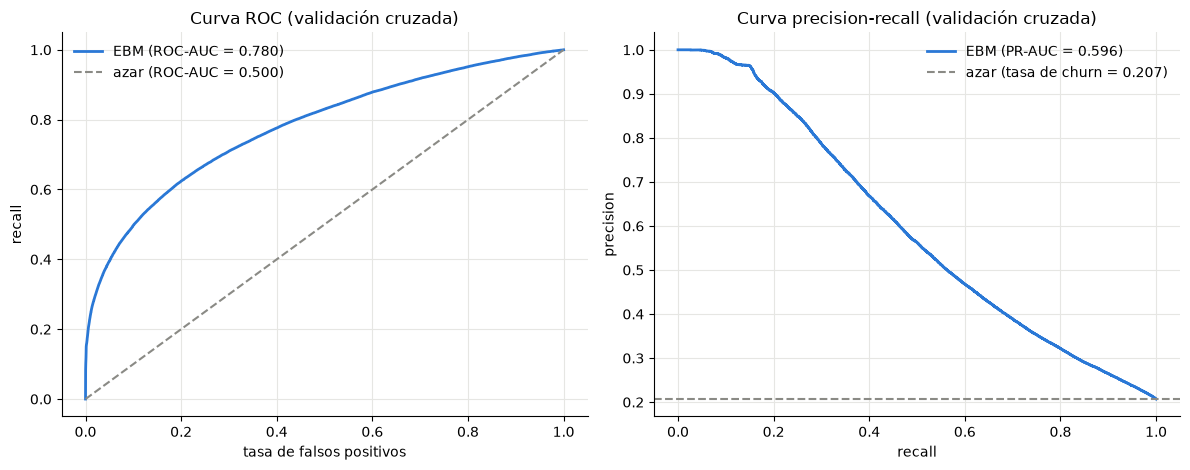

In [35]:
tasa_churn = y_validacion.mean()
fpr, tpr, _ = roc_curve(y_validacion, probabilidad_validacion)
precision, recall, _ = precision_recall_curve(y_validacion, probabilidad_validacion)
roc_auc = roc_auc_score(y_validacion, probabilidad_validacion)
pr_auc = average_precision_score(y_validacion, probabilidad_validacion)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, color=COLOR_MODELO, linewidth=2, label=f"{MODELO_FINAL} (ROC-AUC = {roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar (ROC-AUC = 0.500)")
dar_formato(axes[0], "Curva ROC (validación cruzada)", "tasa de falsos positivos", "recall")

axes[1].plot(recall, precision, color=COLOR_MODELO, linewidth=2, label=f"{MODELO_FINAL} (PR-AUC = {pr_auc:.3f})")
axes[1].axhline(tasa_churn, color=COLOR_AZAR, linewidth=1.5, linestyle="--", label=f"azar (tasa de churn = {tasa_churn:.3f})")
dar_formato(axes[1], "Curva precision-recall (validación cruzada)", "recall", "precision")
plt.tight_layout()
guardar("roc_pr_validacion")
plt.show()

- El modelo supera ampliamente al azar: ROC-AUC de 0,780 frente a 0,500 y PR-AUC de 0,596 frente a 0,207, la tasa de churn.
- La precision es cercana a 1 en los clientes de mayor riesgo y baja a medida que se amplía la cobertura. Con un recall de 0,5 ronda 0,56, más del doble de la tasa de churn.


### 7.2 Curvas de ganancia acumulada y lift


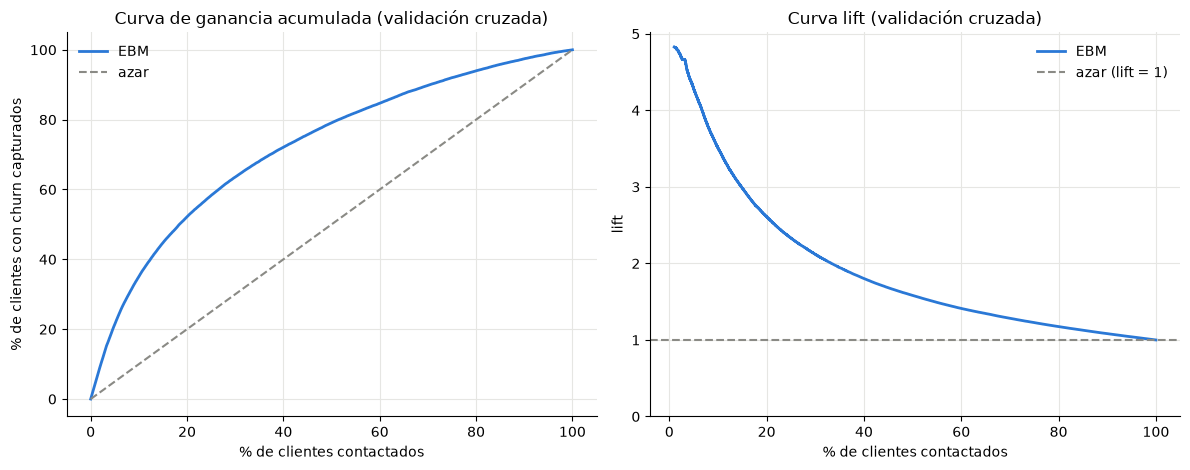

In [36]:
def curva_acumulada(y, probabilidad):
    # Ganancia acumulada y lift al recorrer los clientes de mayor a menor probabilidad
    orden = np.argsort(-probabilidad, kind="stable")
    positivos = np.cumsum(y[orden])
    fraccion = np.arange(1, len(y) + 1) / len(y)
    ganancia = positivos / positivos[-1]
    return pd.DataFrame({"fraccion": fraccion, "ganancia": ganancia, "lift": ganancia / fraccion})


curva = curva_acumulada(y_validacion, probabilidad_validacion)
desde_1_pct = curva[curva["fraccion"] >= 0.01]   # con muy pocos clientes el lift es inestable

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(curva["fraccion"] * 100, curva["ganancia"] * 100, color=COLOR_MODELO, linewidth=2, label=MODELO_FINAL)
axes[0].plot([0, 100], [0, 100], color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar")
dar_formato(axes[0], "Curva de ganancia acumulada (validación cruzada)", "% de clientes contactados", "% de clientes con churn capturados")

axes[1].plot(desde_1_pct["fraccion"] * 100, desde_1_pct["lift"], color=COLOR_MODELO, linewidth=2, label=MODELO_FINAL)
axes[1].axhline(1, color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar (lift = 1)")
axes[1].set_ylim(bottom=0)
dar_formato(axes[1], "Curva lift (validación cruzada)", "% de clientes contactados", "lift")
plt.tight_layout()
guardar("ganancia_lift_validacion")
plt.show()

In [37]:
# Lectura de las curvas en algunos puntos, sin fijar un umbral
PUNTOS = [0.05, 0.10, 0.20, 0.30, 0.50]
posiciones = [int(np.ceil(p * len(curva))) - 1 for p in PUNTOS]
(curva.iloc[posiciones]
 .assign(**{"% de clientes contactados": lambda d: d["fraccion"] * 100,
            "% de churn capturado": lambda d: d["ganancia"] * 100})
 [["% de clientes contactados", "% de churn capturado", "lift"]]
 .round(2).reset_index(drop=True))

,% de clientes contactados,% de churn capturado,lift
0,5.0000,21.4000,4.2800
1,10.0000,35.0800,3.5100
2,20.0000,52.1900,2.6100
3,30.0000,63.5500,2.1200
4,50.0000,79.0900,1.5800


- Vemos que con el 30% de los clientes contactados, capturamos más del 60%  del churn y somos 2,12 veces mejores que el azar.


## 8. Evaluación final en `test`

Entrenamos el modelo final con todo `train` y lo evaluamos con los clientes de `test`, con las mismas curvas de la sección anterior.

In [38]:
variables = ESCENARIOS["principal"]
test_ordenado = test.sort_values(LLAVE).reset_index(drop=True)
y_test = test_ordenado[OBJETIVO].astype(int).to_numpy()

# Las predicciones se calculan una sola vez y al volver a correr la celda se leen del archivo
ruta = DIR_RESULTADOS / f"{nombre_archivo('predicciones_test', 'principal', MODELO_FINAL)}.csv"
if ruta.exists():
    predicciones_test = pd.read_csv(ruta)
else:
    modelo_entrenado = clone(modelo_final).fit(train[variables], y_train)
    predicciones_test = pd.DataFrame({LLAVE: test_ordenado[LLAVE],
                                      "probabilidad": modelo_entrenado.predict_proba(test_ordenado[variables])[:, 1]})
    predicciones_test.to_csv(ruta, index=False)

probabilidad_test = (test_ordenado[[LLAVE]].merge(predicciones_test, on=LLAVE, how="left", validate="one_to_one")
                     ["probabilidad"].to_numpy())
assert not np.isnan(probabilidad_test).any()

pd.DataFrame({"validación cruzada": {"ROC-AUC": roc_auc_score(y_validacion, probabilidad_validacion),
                                     "PR-AUC": average_precision_score(y_validacion, probabilidad_validacion)},
              "test": {"ROC-AUC": roc_auc_score(y_test, probabilidad_test),
                       "PR-AUC": average_precision_score(y_test, probabilidad_test)}}
             ).assign(diferencia=lambda d: d["test"] - d["validación cruzada"]).style.format("{:.5f}")

,validación cruzada,test,diferencia
ROC-AUC,0.78011,0.78108,0.00097
PR-AUC,0.59583,0.59633,0.00050


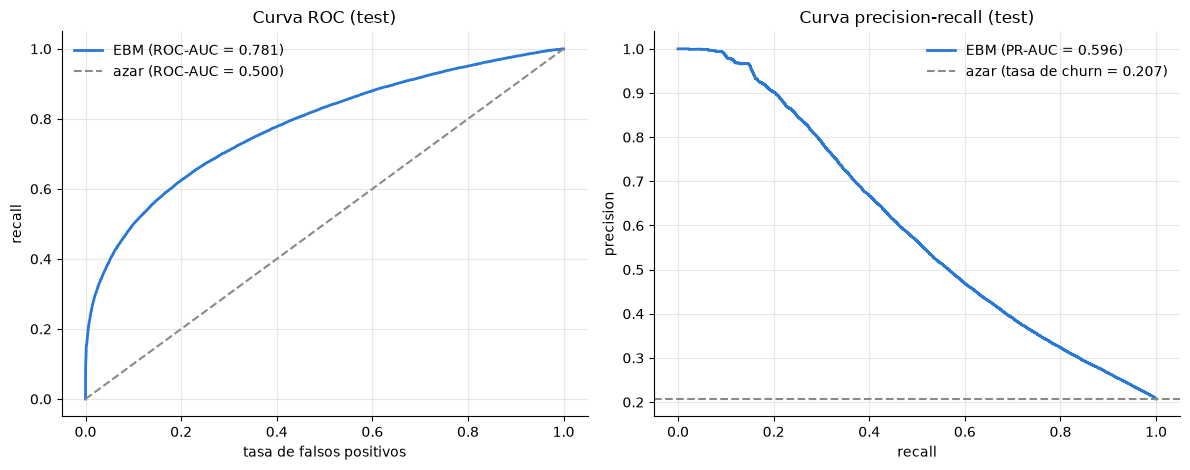

In [39]:
tasa_churn_test = y_test.mean()
fpr_test, tpr_test, _ = roc_curve(y_test, probabilidad_test)
precision_test, recall_test, _ = precision_recall_curve(y_test, probabilidad_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr_test, tpr_test, color=COLOR_MODELO, linewidth=2,
             label=f"{MODELO_FINAL} (ROC-AUC = {roc_auc_score(y_test, probabilidad_test):.3f})")
axes[0].plot([0, 1], [0, 1], color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar (ROC-AUC = 0.500)")
dar_formato(axes[0], "Curva ROC (test)", "tasa de falsos positivos", "recall")

axes[1].plot(recall_test, precision_test, color=COLOR_MODELO, linewidth=2,
             label=f"{MODELO_FINAL} (PR-AUC = {average_precision_score(y_test, probabilidad_test):.3f})")
axes[1].axhline(tasa_churn_test, color=COLOR_AZAR, linewidth=1.5, linestyle="--", label=f"azar (tasa de churn = {tasa_churn_test:.3f})")
dar_formato(axes[1], "Curva precision-recall (test)", "recall", "precision")
plt.tight_layout()
guardar("roc_pr_test")
plt.show()

- En `test` el ROC-AUC es 0,7811 y el PR-AUC 0,5963, frente a 0,7801 y 0,5958 en validación cruzada. Las diferencias son menores a 0,001, así que el modelo mantiene su desempeño en este conjunto de datos.

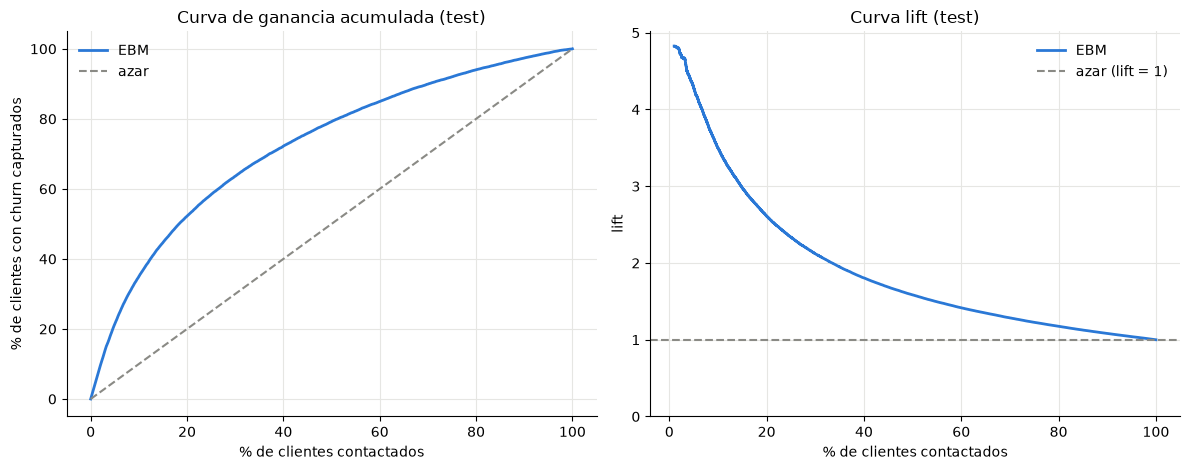

In [40]:
curva_test = curva_acumulada(y_test, probabilidad_test)
desde_1_pct_test = curva_test[curva_test["fraccion"] >= 0.01]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(curva_test["fraccion"] * 100, curva_test["ganancia"] * 100, color=COLOR_MODELO, linewidth=2, label=MODELO_FINAL)
axes[0].plot([0, 100], [0, 100], color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar")
dar_formato(axes[0], "Curva de ganancia acumulada (test)", "% de clientes contactados", "% de clientes con churn capturados")

axes[1].plot(desde_1_pct_test["fraccion"] * 100, desde_1_pct_test["lift"], color=COLOR_MODELO, linewidth=2, label=MODELO_FINAL)
axes[1].axhline(1, color=COLOR_AZAR, linewidth=1.5, linestyle="--", label="azar (lift = 1)")
axes[1].set_ylim(bottom=0)
dar_formato(axes[1], "Curva lift (test)", "% de clientes contactados", "lift")
plt.tight_layout()
guardar("ganancia_lift_test")
plt.show()


- Las curvas tienen la misma forma que en la sección 7. Contactar al 10 % de los clientes con mayor riesgo captura el 35,0 % del churn (lift de 3,50), al 20 % el 52,2 % y al 50 % el 79,2 %. El churn capturado difiere como máximo 0,13 puntos del de validación.

In [41]:
curva_validacion = curva_acumulada(y_validacion, probabilidad_validacion)


def leer_curva(curva, porcentajes):
    # Valores de la curva al contactar cada porcentaje de clientes
    return curva.iloc[[int(np.ceil(p / 100 * len(curva))) - 1 for p in porcentajes]].reset_index(drop=True)


PORCENTAJES = [5, 10, 20, 30, 50]
lectura_test, lectura_validacion = leer_curva(curva_test, PORCENTAJES), leer_curva(curva_validacion, PORCENTAJES)
pd.DataFrame({"% de clientes contactados": PORCENTAJES,
              "% de churn capturado (test)": lectura_test["ganancia"] * 100,
              "% de churn capturado (validación)": lectura_validacion["ganancia"] * 100,
              "lift (test)": lectura_test["lift"],
              "lift (validación)": lectura_validacion["lift"]}).round(2)

,% de clientes contactados,% de churn capturado (test),% de churn capturado (validación),lift (test),lift (validación)
0,5,21.4200,21.4000,4.2800,4.2800
1,10,35.0100,35.0800,3.5000,3.5100
2,20,52.2100,52.1900,2.6100,2.6100
3,30,63.6200,63.5500,2.1200,2.1200
4,50,79.2200,79.0900,1.5800,1.5800


## 9. Caso de uso y limitaciones

La interpretación del modelo final y el análisis de sesgos están en `03_xai.ipynb`.


### 9.1 Caso de uso: priorización por riesgo y valor

Combinamos la probabilidad de churn con `lifetime_value` para priorizar que clientes necesitan acciones de retención urgente y revisamos cómo queda la lista de clientes priorizados.

El valor en riesgo de cada cliente es su probabilidad de churn por su `lifetime_value` (decisión 33 del EDA). Usamos los clientes de `test` y comparamos este orden con priorizar solo por probabilidad, solo por valor o al azar. El valor perdido es la suma del `lifetime_value` de los clientes que abandonan.


In [42]:
priorizacion = test_ordenado[[LLAVE, "lifetime_value"]].assign(churn=y_test, probabilidad=probabilidad_test)
priorizacion["valor_en_riesgo"] = priorizacion["probabilidad"] * priorizacion["lifetime_value"]

CRITERIOS = {"valor en riesgo": "valor_en_riesgo", "solo probabilidad": "probabilidad", "solo lifetime_value": "lifetime_value"}
PORCENTAJES_LISTA = [5, 10, 20, 30]
churn_total = priorizacion["churn"].sum()
valor_perdido_total = priorizacion.loc[priorizacion["churn"] == 1, "lifetime_value"].sum()


def primeros(columna, porcentaje):
    # Clientes en el porcentaje superior de la lista ordenada por `columna`
    n = int(np.ceil(porcentaje / 100 * len(priorizacion)))
    return priorizacion.sort_values(columna, ascending=False, kind="stable").head(n)


filas = []
for criterio, columna in CRITERIOS.items():
    for porcentaje in PORCENTAJES_LISTA:
        abandonan = primeros(columna, porcentaje).query("churn == 1")
        filas.append({"% de clientes contactados": porcentaje, "criterio": criterio,
                      "% de churn capturado": len(abandonan) / churn_total * 100,
                      "% del valor perdido capturado": abandonan["lifetime_value"].sum() / valor_perdido_total * 100})
filas += [{"% de clientes contactados": p, "criterio": "azar", "% de churn capturado": p, "% del valor perdido capturado": p}
          for p in PORCENTAJES_LISTA]
(pd.DataFrame(filas).set_index(["% de clientes contactados", "criterio"]).sort_index()
 .style.format("{:.1f}"))

In [43]:
filas = []
for porcentaje in PORCENTAJES_LISTA + [100]:
    lista = primeros("valor_en_riesgo", porcentaje)
    filas.append({"% de clientes contactados": porcentaje, "clientes": len(lista),
                  "probabilidad media": lista["probabilidad"].mean(),
                  "tasa real de churn": lista["churn"].mean(),
                  "lifetime_value medio": lista["lifetime_value"].mean(),
                  "valor en riesgo total": lista["valor_en_riesgo"].sum()})
display(pd.DataFrame(filas).set_index("% de clientes contactados")
        .style.format({"clientes": "{:,.0f}", "probabilidad media": "{:.3f}", "tasa real de churn": "{:.3f}",
                       "lifetime_value medio": "{:,.0f}", "valor en riesgo total": "{:,.0f}"}))

# Primeros clientes de la lista
(primeros("valor_en_riesgo", 100).head(10)[[LLAVE, "probabilidad", "lifetime_value", "valor_en_riesgo"]]
 .reset_index(drop=True).style.format({"probabilidad": "{:.3f}", "lifetime_value": "{:,.0f}", "valor_en_riesgo": "{:,.0f}"}))

,clientes,probabilidad media,tasa real de churn,lifetime_value medio,valor en riesgo total
% de clientes contactados,,,,,
5,"7,500",0.233,0.233,"1,495,092","1,918,292,957"
10,"15,000",0.230,0.230,"1,385,382","3,378,232,280"
20,"30,000",0.221,0.222,"1,258,463","5,709,452,492"
30,"45,000",0.215,0.215,"1,172,050","7,549,232,413"
100,"150,000",0.207,0.207,"678,139","12,944,013,769"


,customer_id,probabilidad,lifetime_value,valor_en_riesgo
0,1110192,0.221,"1,815,201","401,743"
1,1186382,0.285,"1,396,885","398,002"
2,1069066,0.250,"1,590,763","397,867"
3,1413588,0.210,"1,873,854","394,176"
4,1477096,0.262,"1,499,945","392,554"
5,1483902,0.298,"1,313,658","391,143"
6,1173878,0.210,"1,861,078","390,600"
7,1049832,0.213,"1,831,962","390,307"
8,1086683,0.300,"1,301,415","390,073"
9,1138295,0.274,"1,421,040","389,156"


- Priorizar por valor en riesgo es lo que más valor protege: al contactar al 10 % de los clientes captura el 25,9 % del valor perdido, frente a 19,4 % solo con `lifetime_value`, 9,1 % solo con la probabilidad del modelo y 10 % al azar.
- A cambio, captura casi el mismo churn que el azar (11,1 % frente a 10 %). En ese tramo el `lifetime_value` medio es el doble del general (1.385.382 frente a 678.139), pero la tasa de churn apenas sube (23,0 % frente a 20,7 %), así que el valor domina el orden.
- Priorizar solo por probabilidad captura el 35,0 % del churn, pero solo el 9,1 % del valor perdido, porque los clientes de mayor riesgo son de bajo valor.

El criterio depende del objetivo de la campaña: valor en riesgo para proteger ingresos, y solo probabilidad para reducir el número de clientes que abandonan.


**Priorizamos solo con la probabilidad de churn del modelo.** Es el criterio que responde al objetivo de reducir el abandono, mientras que el valor en riesgo termina ordenando casi solo por `lifetime_value`. 

Los clientes de mayor valor abandonan mucho menos, así que el churn que captura esta lista corresponde sobre todo a clientes de menor valor.


### 9.2 Limitaciones

**Datos y etiqueta**

- Como son datos sintéticos, **la etiqueta parece construida.** `churn` es exactamente `churn_risk_score >= 60`, y ese puntaje se explica casi por completo con 3 variables. La documentación del dataset no lo aclara y, sin el código del generador, no queda demostrado.
- **Retirar esas 3 variables es un supuesto:** El ROC-AUC cercano a 1,0 de las 7 variables no mide la capacidad de predecir el abandono real (sección 5.6), y por eso partimos de que forman la etiqueta (sección 5.7).
- **Posible fuga residual:** Las 4 variables finales pueden conservar parte de la señal de la etiqueta (sección 5.7), así que el ROC-AUC de 0,78 puede sobrestimar la capacidad real del modelo.
- Aunque el modelo de datos es relacional, toda la señal está en las variables de `customer_summary`. El resto de tablas casi no tiene información de valor para la etiqueta (sección 4.2). Además, `summary_total_orders` no coincide con los pedidos de `orders` en el 99,3 % de los clientes (decisión 4), así que no podemos confirmar que estas variables reflejen compras reales.
- No se sabe cuándo ocurrió el abandono (decisión 20). La partición es aleatoria, alguna variable pudo medirse después del abandono y el modelo no se evaluó con clientes futuros.

**Modelo**

- **Elección por empate:** El EBM se eligió por su interpretabilidad, no porque rinda mejor, y la búsqueda de sus hiperparámetros fue de solo 10 ensayos.
- **Variables relacionadas.** `total_spent` es el producto de `summary_total_orders` y `average_order_value` (decisión 31), así que sus efectos se interpretan en conjunto (sección 5.4).

El análisis de sesgos está en `03_xai.ipynb`.


## 10. Modelo final

Guardamos el modelo final, sus variables y su configuración para `03_xai.ipynb` y la API. Es el modelo evaluado en la sección 8, entrenado con todo
`train` y sin `test`, como confirma la verificación de esta sección.


In [44]:
DIR_MODELO = DIR_RESULTADOS / "modelo_final"
DIR_MODELO.mkdir(exist_ok=True)
RUTA_MODELO = DIR_MODELO / "modelo.joblib"
RUTA_CONFIGURACION = DIR_MODELO / "configuracion.json"
variables = ESCENARIOS["principal"]

if not RUTA_MODELO.exists():
    if "modelo_entrenado" not in globals():
        raise RuntimeError("El modelo de la sección 8 ya no está en memoria. No se reentrena aquí para no guardar otro modelo.")
    joblib.dump(modelo_entrenado, RUTA_MODELO)
modelo_guardado = joblib.load(RUTA_MODELO)

configuracion = {
    "modelo": MODELO_FINAL,
    "escenario": "principal",
    "variables": variables,
    "variables_retiradas_por_fuga": VARIABLES_ETIQUETA,
    "objetivo": OBJETIVO,
    "llave": LLAVE,
    "hiperparametros": parametros_optimos[MODELO_FINAL],
    "semilla": SEMILLA,
    "filas_entrenamiento": len(train),
    "metricas": {
        "validacion_cruzada": {"roc_auc": float(roc_auc_score(y_validacion, probabilidad_validacion)),
                               "pr_auc": float(average_precision_score(y_validacion, probabilidad_validacion))},
        "test": {"roc_auc": float(roc_auc_score(y_test, probabilidad_test)),
                 "pr_auc": float(average_precision_score(y_test, probabilidad_test))},
    },
    "versiones": {paquete: version(paquete) for paquete in ["interpret-core", "scikit-learn", "pandas", "numpy"]},
}
RUTA_CONFIGURACION.write_text(json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(configuracion, ensure_ascii=False, indent=2))

{
  "modelo": "EBM",
  "escenario": "principal",
  "variables": [
    "summary_total_orders",
    "total_spent",
    "average_order_value",
    "total_returns"
  ],
  "variables_retiradas_por_fuga": [
    "last_purchase_days",
    "return_rate",
    "purchase_frequency"
  ],
  "objetivo": "churn",
  "llave": "customer_id",
  "hiperparametros": {
    "interactions": 1,
    "learning_rate": 0.033994812107955644,
    "max_leaves": 2,
    "min_samples_leaf": 4
  },
  "semilla": 42,
  "filas_entrenamiento": 350000,
  "metricas": {
    "validacion_cruzada": {
      "roc_auc": 0.7801100009197721,
      "pr_auc": 0.595832429737294
    },
    "test": {
      "roc_auc": 0.7810836772242771,
      "pr_auc": 0.5963344019512526
    }
  },
  "versiones": {
    "interpret-core": "0.7.8",
    "scikit-learn": "1.9.1",
    "pandas": "3.1.0",
    "numpy": "2.4.6"
  }
}


In [45]:
# El modelo cargado desde el archivo debe dar las mismas probabilidades que se evaluaron en la sección 8
probabilidad_guardado = modelo_guardado.predict_proba(test_ordenado[variables])[:, 1]
print(f"diferencia máxima de probabilidad frente a la sección 8: {np.abs(probabilidad_guardado - probabilidad_test).max():.2e}")
print(f"ROC-AUC en test del modelo cargado: {roc_auc_score(y_test, probabilidad_guardado):.5f}")

diferencia máxima de probabilidad frente a la sección 8: 0.00e+00
ROC-AUC en test del modelo cargado: 0.78108


Subimos al bucket todo `data/modelado`, con el modelo final incluido, para que la descarga de la sección 1.1 entregue los
mismos resultados a cualquiera que ejecute el notebook. Los archivos del bucket se reemplazan, por eso la subida
solo ocurre si `SUBIR_A_S3` es verdadero.


In [ ]:
SUBIR_A_S3 = False   # solo se activa para actualizar los resultados compartidos

if SUBIR_A_S3:
    archivos_subidos = data.subir_modelado()
    print(f"archivos subidos a S3: {archivos_subidos}")
else:
    print("No se subió nada a S3 (SUBIR_A_S3 = False)")

archivos subidos a S3: 25
